# 13 — Understand the datasets before building with them

## Objective

Inspect the real records, files, pages, labels, and relationships that make up this project before using any dataset for retrieval, parsing, question answering, or evaluation. By the end, we should be able to explain what one observation means in every dataset, what is actually available locally, and what is still missing.

### Current local snapshot

- The project annotation tables register three PDFs, but the verified question table is empty.
- MMLongBench metadata contains 1,091 questions referring to 135 documents; one referenced PDF is local.
- ViDoRe contains 1,920 queries and 8,808 query–page relevance rows; the page-image corpus is not local.
- OmniDocBench contains 1,651 annotated pages and 32,798 layout regions; the referenced page images are not local.

These numbers are a starting snapshot, not hard-coded project assumptions. The cells below recompute them from the local files.

## Concept — grain comes before charts

The grain of a dataset is what one row represents. A question row, a query–page relevance row, and a page-region annotation are different kinds of evidence even if all of them mention documents. Combining them without understanding that difference would produce invalid counts and misleading conclusions.

The inspection order in this notebook is therefore: raw record → field meaning → relationships → quality checks → distributions → project role.

## Setup — local, deterministic, and bounded

This notebook reads only files already present under data/. It does not contact a dataset hub or download missing media.

In [28]:
from pathlib import Path
from collections import Counter
import ast
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import numpy as np
import pandas as pd
import pymupdf
from datasets import Dataset
from IPython.display import Markdown, display

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 30)

In [29]:
PROJECT_ROOT = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "pyproject.toml").is_file()
)

DATA_DIR = PROJECT_ROOT / "data"
ANNOTATIONS_DIR = DATA_DIR / "annotations"
EXTERNAL_DIR = DATA_DIR / "external"
MMLONG_DIR = EXTERNAL_DIR / "mmlongbench_doc"
VIDORE_DIR = EXTERNAL_DIR / "vidore"
OMNI_DIR = EXTERNAL_DIR / "omnidocbench"

print("Project root:", PROJECT_ROOT)
print("Python:", sys.version.split()[0])
print("Data directory:", DATA_DIR)

Project root: /Users/macbookair/Documents/ENSAE/side project/Multimodal-Document-Intelligence
Python: 3.12.6
Data directory: /Users/macbookair/Documents/ENSAE/side project/Multimodal-Document-Intelligence/data


## 1. Inventory — what is physically present?

A dataset name can hide several separate assets: metadata, questions, relevance labels, PDFs, or page images. We inventory those parts before treating a dataset as usable.

In [30]:
primary_paths = {
    "local document manifest": ANNOTATIONS_DIR / "documents.csv",
    "local question table": ANNOTATIONS_DIR / "questions.csv",
    "illustrative questions": ANNOTATIONS_DIR / "examples" / "questions_illustrative.csv",
    "MMLongBench metadata": MMLONG_DIR / "data" / "train-00000-of-00001.parquet",
    "OmniDocBench annotations": OMNI_DIR / "OmniDocBench.json",
}

for index, arrow_path in enumerate(sorted(VIDORE_DIR.rglob("*.arrow")), start=1):
    primary_paths[f"ViDoRe Arrow table {index}"] = arrow_path

def human_size(byte_count):
    value = float(byte_count)
    for unit in ("B", "KiB", "MiB", "GiB"):
        if value < 1024 or unit == "GiB":
            return f"{value:.1f} {unit}"
        value /= 1024

inventory_rows = []
for asset, path in primary_paths.items():
    inventory_rows.append(
        {
            "asset": asset,
            "relative_path": str(path.relative_to(PROJECT_ROOT)),
            "exists": path.is_file(),
            "size": human_size(path.stat().st_size) if path.is_file() else "missing",
        }
    )

inventory = pd.DataFrame(inventory_rows)
display(inventory)

,asset,relative_path,exists,size
0,local document manifest,data/annotations/documents.csv,True,1.4 KiB
1,local question table,data/annotations/questions.csv,True,159.0 B
2,illustrative questions,data/annotations/examples/questions_illustrative.csv,True,2.0 KiB
3,MMLongBench metadata,data/external/mmlongbench_doc/data/train-00000-of-00001.parquet,True,80.1 KiB
4,OmniDocBench annotations,data/external/omnidocbench/OmniDocBench.json,True,40.3 MiB
5,ViDoRe Arrow table 1,data/external/vidore/cache/vidore___vidore_v3_finance_fr/default-8fae1086fc1b5e90/0.0.0/1d808daa08032ffecdf62da151a7...,True,1023.8 KiB
6,ViDoRe Arrow table 2,data/external/vidore/cache/vidore___vidore_v3_finance_fr/default-fae51a2c737342cf/0.0.0/1d808daa08032ffecdf62da151a7...,True,1.8 MiB


### Four datasets, four grains

| Dataset | Main record | Relationship represented | Natural project use |
|---|---|---|---|
| Local project tables | document or verified question | question → document → evidence pages | controlled project evaluation |
| MMLongBench-Doc | question about a long PDF | question → answer + evidence pages | long-document QA evaluation |
| ViDoRe | query or relevance row | query → relevant corpus page | page retrieval evaluation |
| OmniDocBench | page with layout regions | page → polygons + semantic categories | parsing and layout evaluation |

The rows cannot be concatenated into one universal training table without first designing an explicit target and mapping.

## 2. Local project corpus — the data closest to the research question

The local manifest describes which PDFs belong to the project. The question table is intended to contain human-verified evaluation examples. Illustrative questions are kept separate because they are demonstrations, not ground truth.

In [31]:
documents = pd.read_csv(ANNOTATIONS_DIR / "documents.csv")
questions = pd.read_csv(ANNOTATIONS_DIR / "questions.csv")
illustrative_questions = pd.read_csv(
    ANNOTATIONS_DIR / "examples" / "questions_illustrative.csv"
)

print("documents.csv shape:", documents.shape)
print("questions.csv shape:", questions.shape)
print("illustrative questions shape:", illustrative_questions.shape)

display(documents)
display(questions.head())
display(illustrative_questions.head(3))

documents.csv shape: (3, 12)
questions.csv shape: (0, 14)
illustrative questions shape: (5, 14)


,doc_id,file_path,title,doc_category,source_kind,page_count,language,provenance,usage_rights,known_content,status,notes
0,D001,data/documents/ch2.pdf,"The prior distribution (Bayesian statistics, chapter 2)",lecture_slides,born_digital,68,en,"ENSAE course slides, LaTeX Beamer",unverified: course material; confirm redistribution is allowed (file is already in the public repo),text;table;figure;equation,candidate,Only p.65 has a raster image (figure content is pixels only). Vector plots e.g. p.17. Table p.49. Equations extract ...
1,D002,data/documents/scanned.pdf,EPA sample letter on drinking water (scanned),letter,scanned,3,en,"US EPA Office of Water sample letter, scanned on a Lexmark X792 (from PDF metadata); original URL unknown",unverified: likely public domain as a US federal government work,scanned_text,candidate,Native text is only the overlaid heading 'SAMPLE LETTER' on p.1; pp.2-3 have no native text. Faint date stamp and ci...
2,D003,data/documents/apple_10k.pdf,"Apple Inc. Form 10-K, fiscal year ended 2023-09-30",financial_report,born_digital,74,en,SEC EDGAR filing aapl-20230930; copy distributed with the course lab materials,public SEC filing,text;table,candidate,Printed page labels differ from physical index (physical p.32 = printed 21). Raster images on pp.1 and 30 not review...


,question_id,doc_id,split,question,question_type,evidence_modality,evidence_pages,reference_answer,answer_type,evidence_note,annotator,verified_by,status,notes


,question_id,doc_id,split,question,question_type,evidence_modality,evidence_pages,reference_answer,answer_type,evidence_note,annotator,verified_by,status,notes
0,Q9001,D001,dev,"According to Cromwell's rule as stated in the slides, to what should prior probability 0 never be given?",lookup,text,9.0,A possibility that is not logically impossible.,short_text,"Second bullet, 'Cromwell's rule (Lindley 1985)'",ai-draft,NaN,draft,"ILLUSTRATIVE - not ground truth. Native text is clean here, so text-only should succeed."
1,Q9002,D001,dev,"In the table of usual conjugate pairs, what is the posterior when the sampling model is Poisson(λ) and the prior is ...",lookup,table,49.0,"Ga(a + s, b + n)",short_text,"Table 'Usual conjugate pairs', row Poisson(λ); s = sum of observations, n = sample size",ai-draft,NaN,draft,ILLUSTRATIVE - not ground truth. This row extracts cleanly; the Normal rows are garbled by native extraction.
2,Q9003,D001,dev,"In the Random Effects example figure, which curve is higher for large values of τ² (for example τ² > 5): the integra...",comparison,figure,65.0,The profile likelihood L̂(τ²),short_text,"Raster figure reproduced from Berger, Liseo and Wolpert (1999), Fig. 1; curve labels are inside the image",ai-draft,NaN,draft,"ILLUSTRATIVE - not ground truth. Native text has only the caption, which names both curves but not their ordering: e..."


### How to read the local records

- doc_id is the stable document key shared by the tables.
- source_kind describes whether readable content is stored as PDF text, pixels, or both.
- known_content describes evidence types known to exist in the document; it is not a model prediction.
- question_id identifies a single evaluation question.
- evidence_pages uses 1-based physical PDF page numbers.
- status and verified_by determine whether a question is permitted in evaluation.

The illustrative rows show the intended shape, but their ai-draft status prevents them from being scored.

In [32]:
local_document_rows = []
for row in documents.itertuples(index=False):
    pdf_path = PROJECT_ROOT / row.file_path
    observed_pages = None
    if pdf_path.is_file():
        with pymupdf.open(pdf_path) as pdf:
            observed_pages = pdf.page_count
    local_document_rows.append(
        {
            "doc_id": row.doc_id,
            "title": row.title,
            "source_kind": row.source_kind,
            "declared_pages": row.page_count,
            "observed_pages": observed_pages,
            "file_exists": pdf_path.is_file(),
            "status": row.status,
        }
    )

local_document_check = pd.DataFrame(local_document_rows)
display(local_document_check)

,doc_id,title,source_kind,declared_pages,observed_pages,file_exists,status
0,D001,"The prior distribution (Bayesian statistics, chapter 2)",born_digital,68,68,True,candidate
1,D002,EPA sample letter on drinking water (scanned),scanned,3,3,True,candidate
2,D003,"Apple Inc. Form 10-K, fiscal year ended 2023-09-30",born_digital,74,74,True,candidate


### What the local pages actually look like

These are real pages selected from the manifest notes to expose different document structures. Rendering the page is important because native PDF text alone cannot reveal scanned text, raster figures, or visual table structure. Each output below is a separate high-resolution detail crop rather than a compressed full-page thumbnail; the crop changes only the visible area, not the underlying page content.

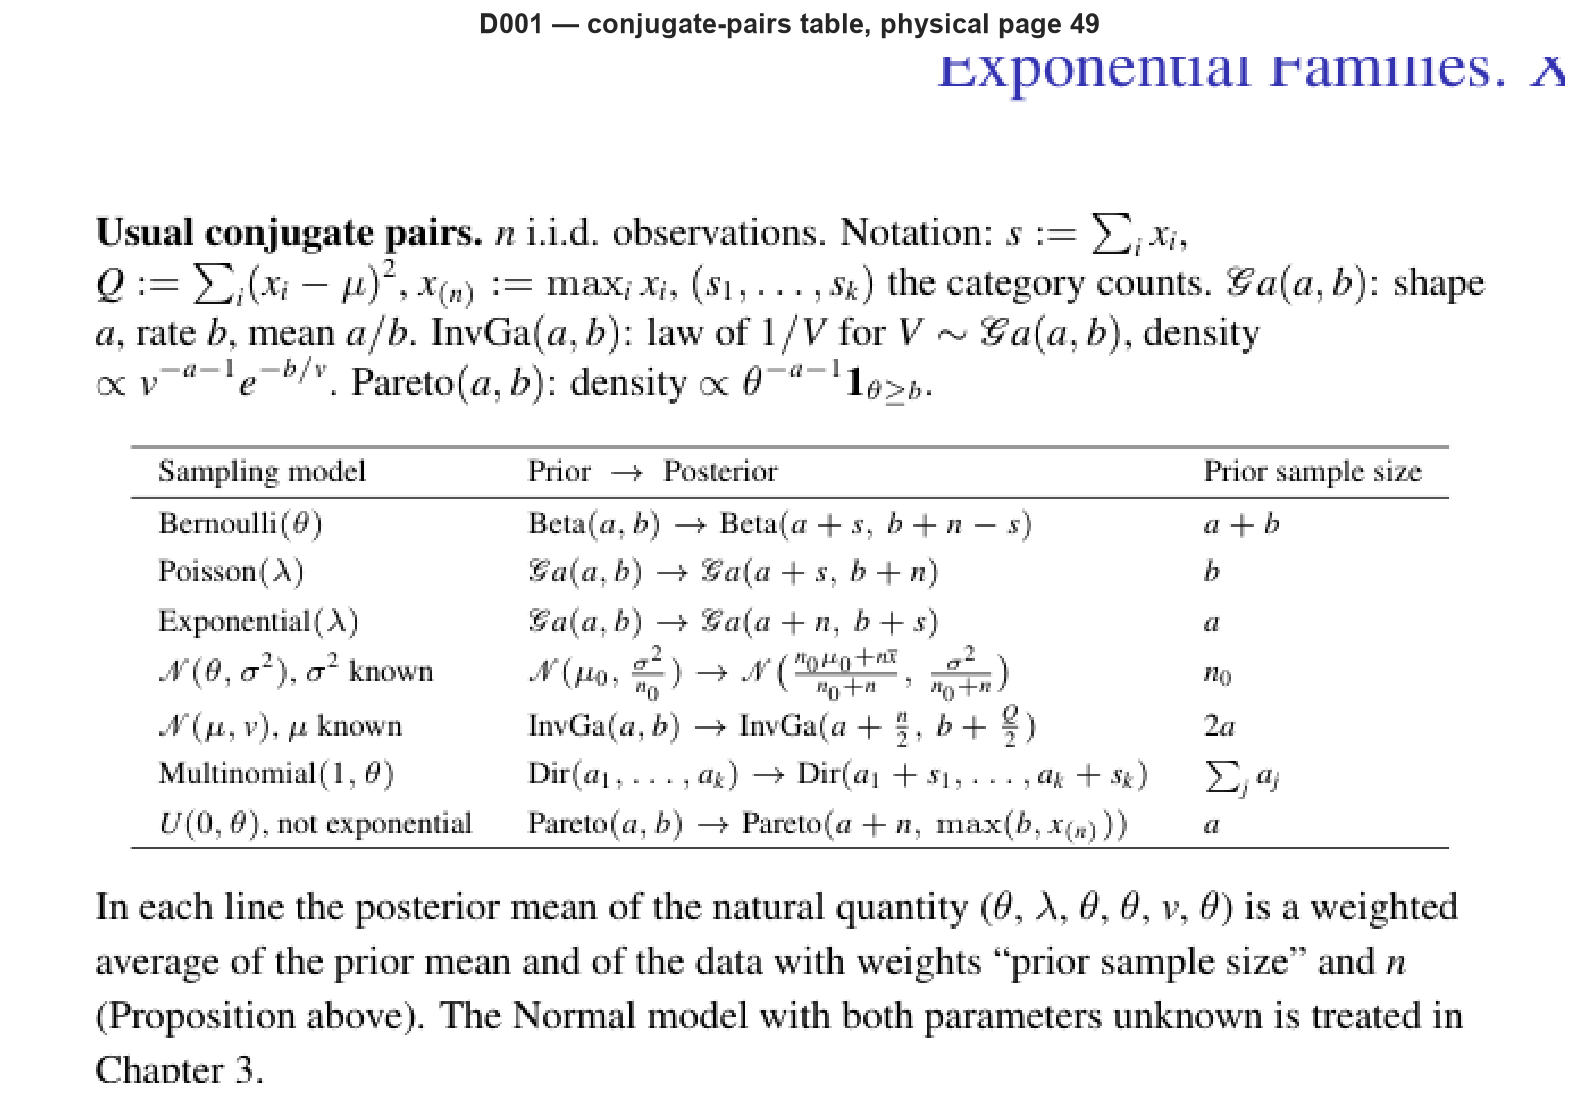

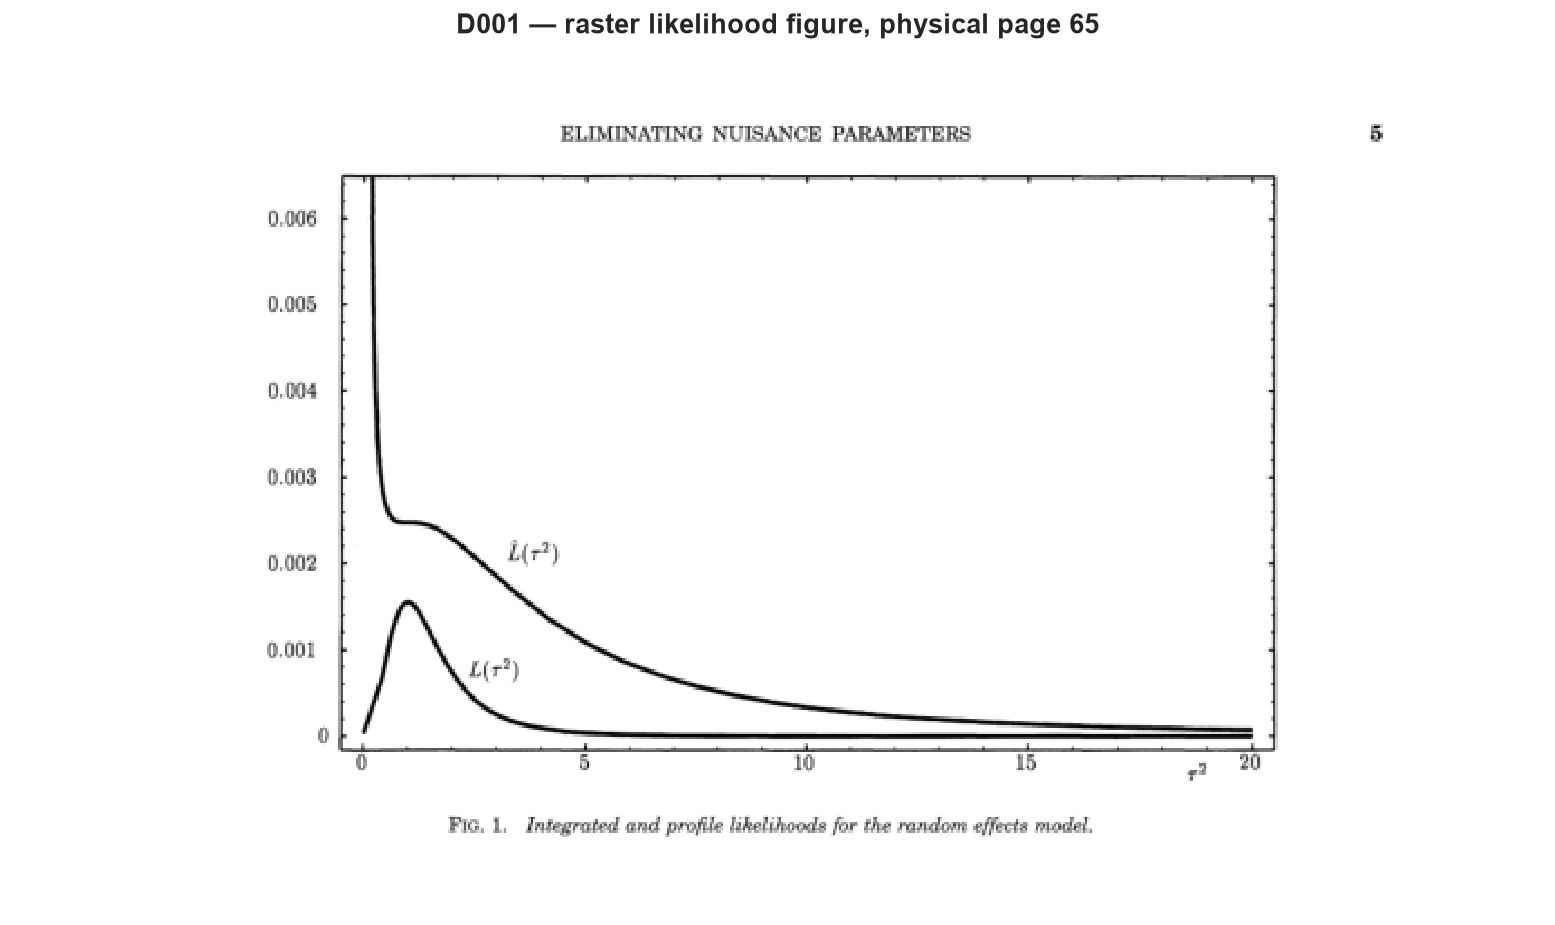

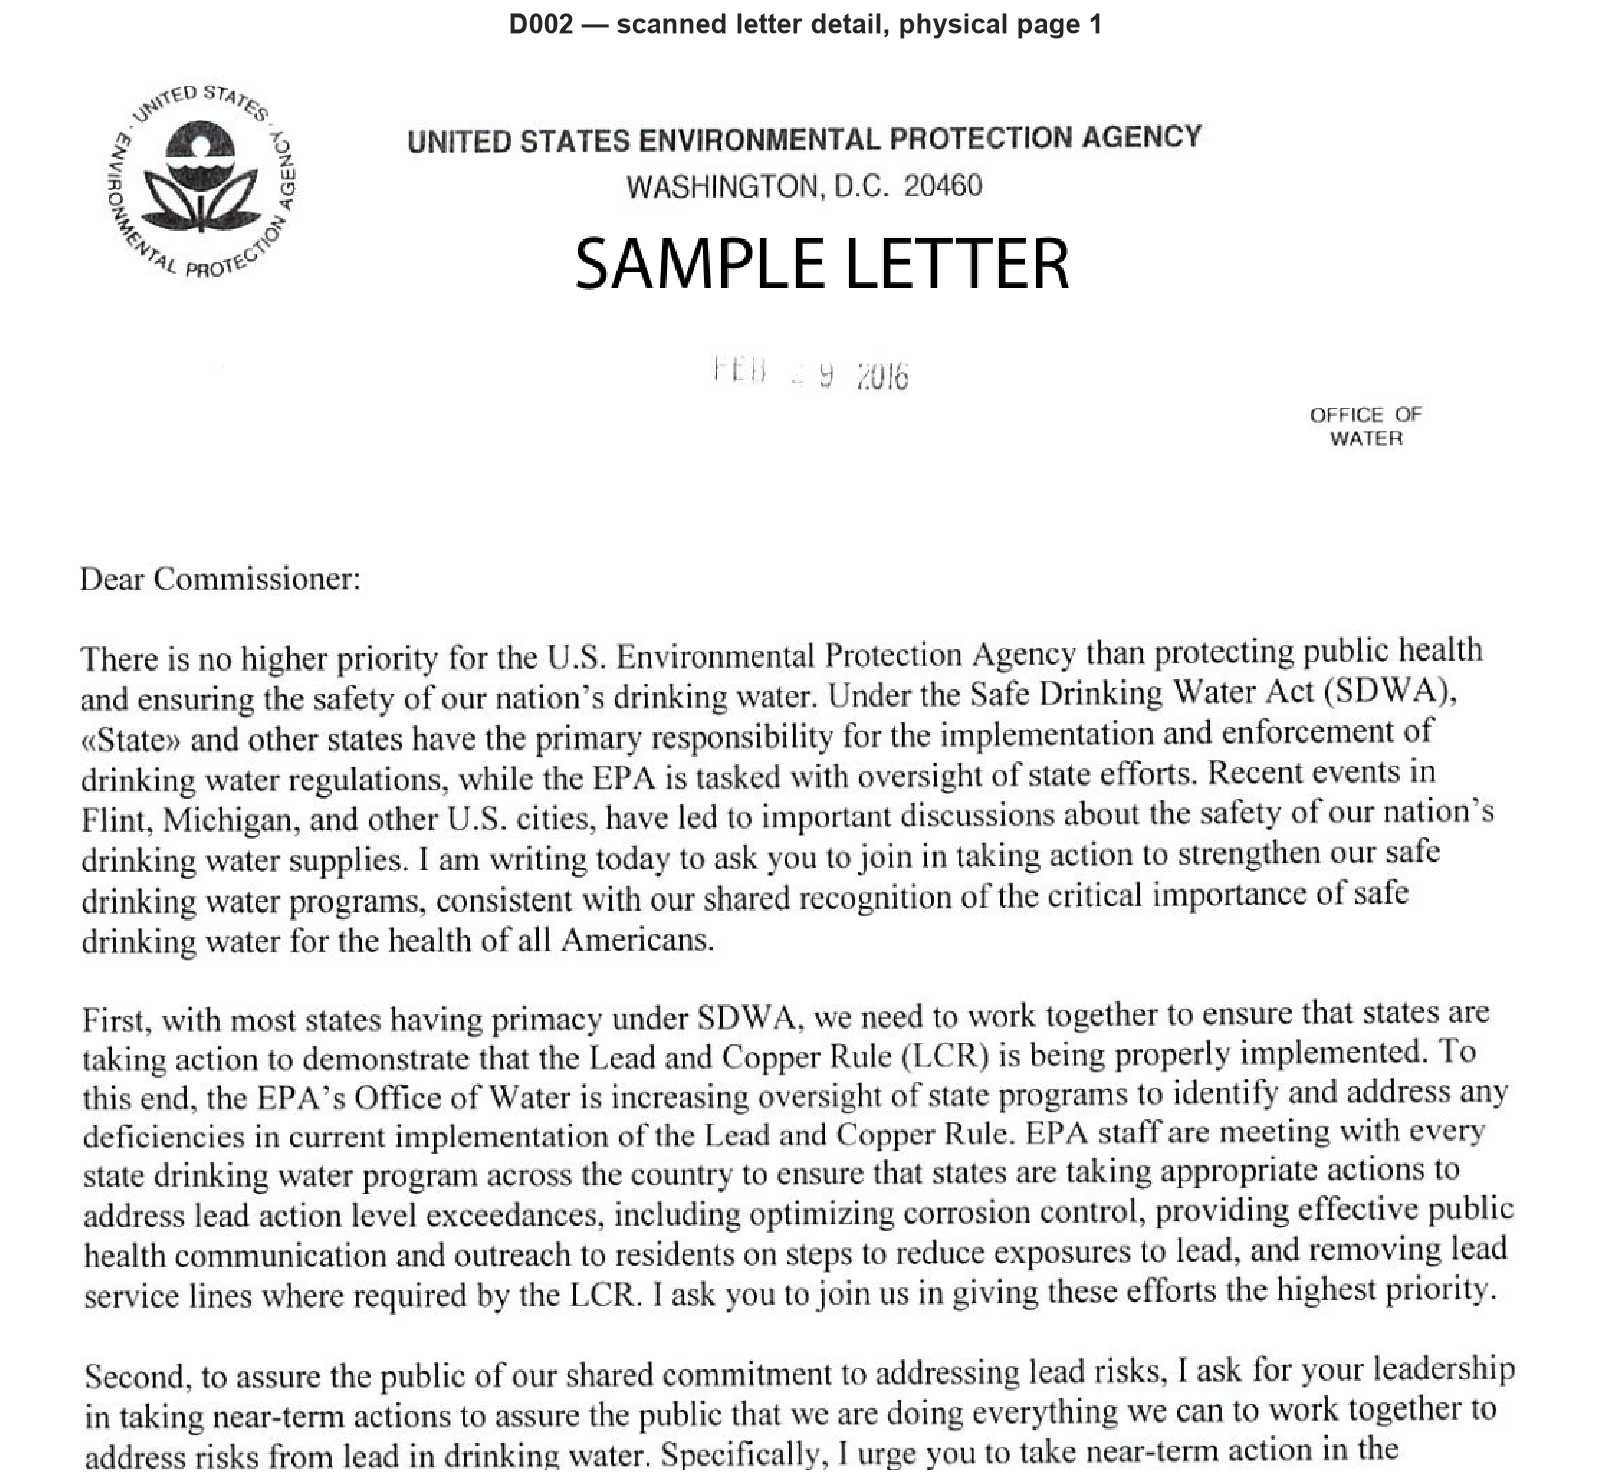

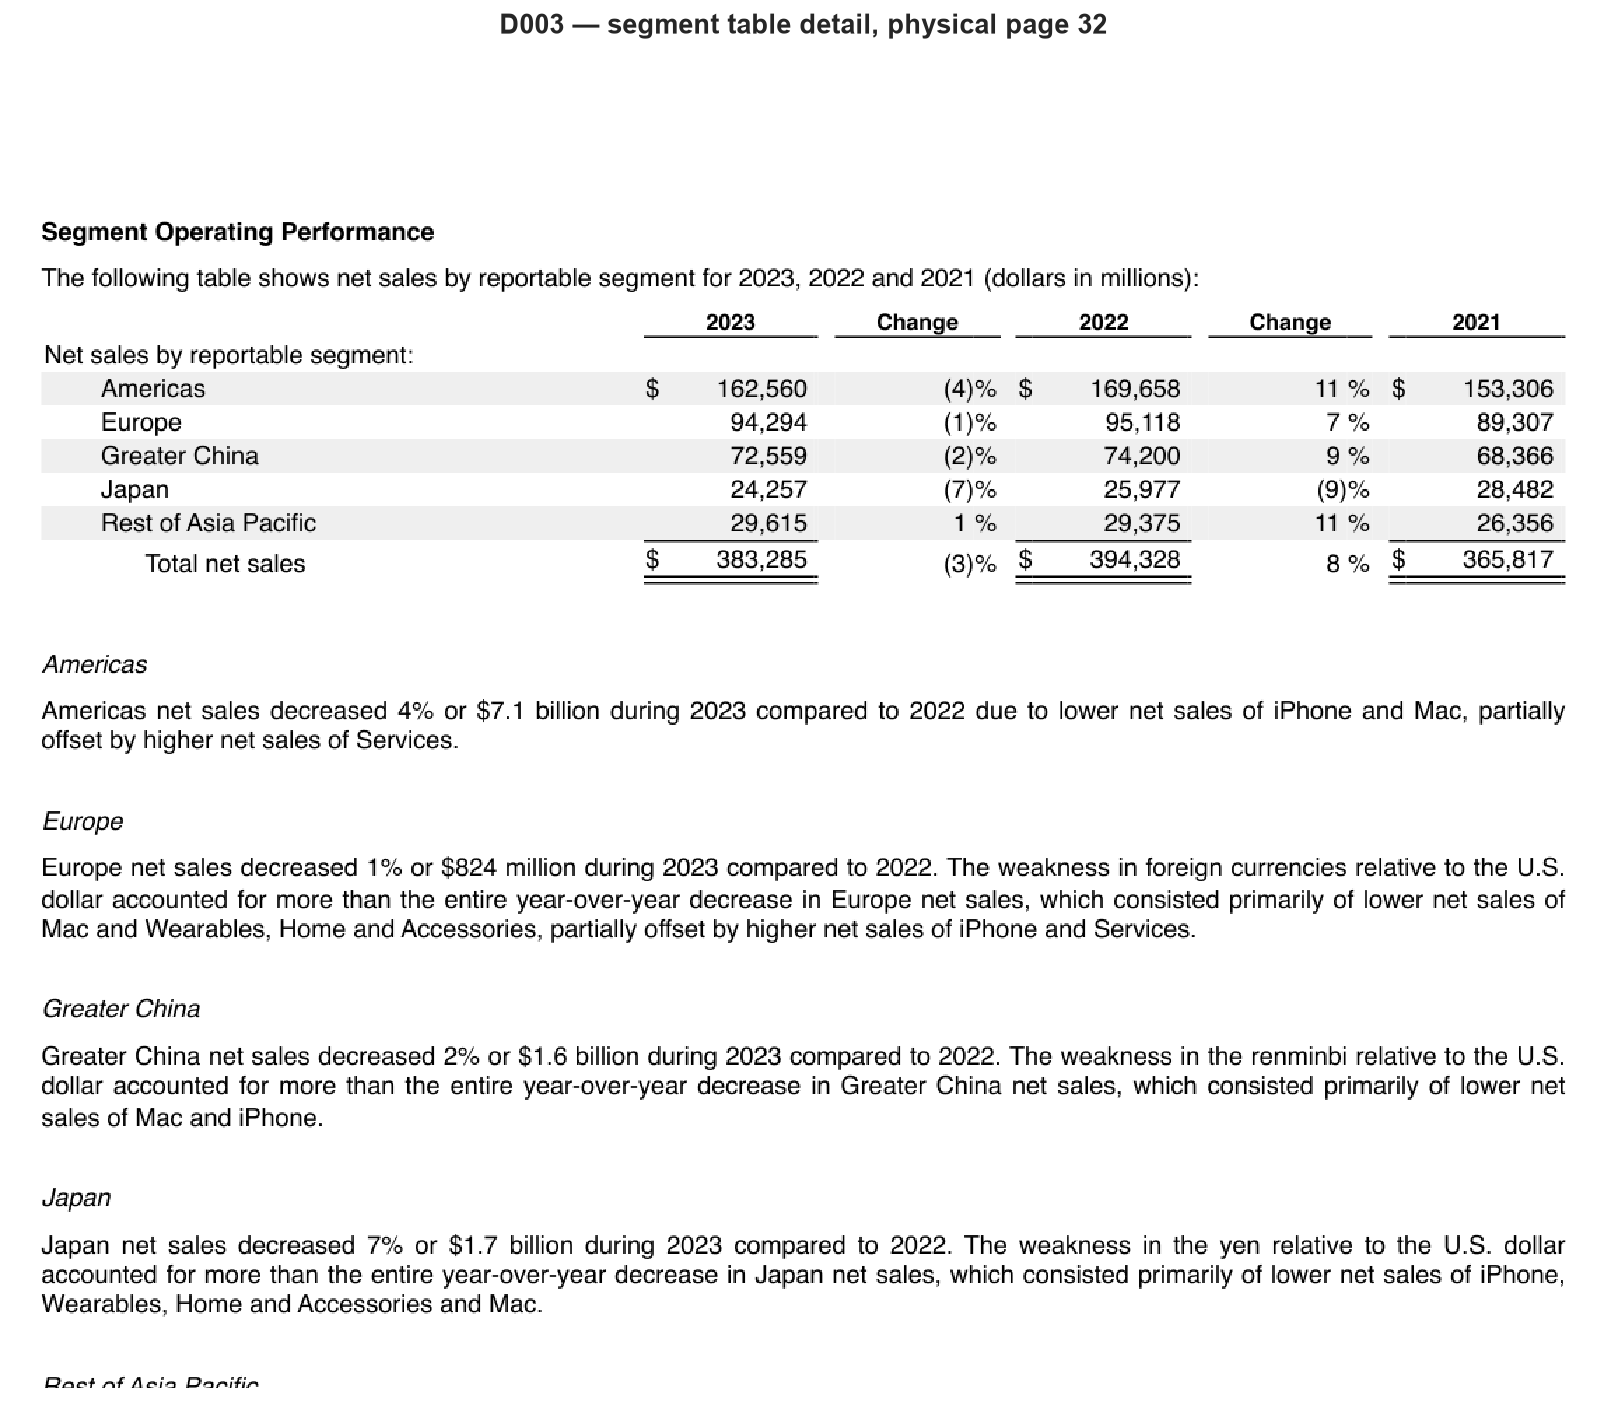

In [33]:
page_examples = [
    {
        "label": "D001 — conjugate-pairs table, physical page 49",
        "path": DATA_DIR / "documents" / "ch2.pdf",
        "physical_page": 49,
        "crop": (0.03, 0.05, 0.97, 0.88),
    },
    {
        "label": "D001 — raster likelihood figure, physical page 65",
        "path": DATA_DIR / "documents" / "ch2.pdf",
        "physical_page": 65,
        "crop": (0.03, 0.14, 0.97, 0.84),
    },
    {
        "label": "D002 — scanned letter detail, physical page 1",
        "path": DATA_DIR / "documents" / "scanned.pdf",
        "physical_page": 1,
        "crop": (0.05, 0.04, 0.95, 0.66),
    },
    {
        "label": "D003 — segment table detail, physical page 32",
        "path": DATA_DIR / "documents" / "apple_10k.pdf",
        "physical_page": 32,
        "crop": (0.04, 0.04, 0.96, 0.64),
    },
]

for example in page_examples:
    with pymupdf.open(example["path"]) as pdf:
        page = pdf[example["physical_page"] - 1]
        page_rectangle = page.rect
        left, top, right, bottom = example["crop"]
        crop_rectangle = pymupdf.Rect(
            page_rectangle.x0 + left * page_rectangle.width,
            page_rectangle.y0 + top * page_rectangle.height,
            page_rectangle.x0 + right * page_rectangle.width,
            page_rectangle.y0 + bottom * page_rectangle.height,
        )
        pixmap = page.get_pixmap(
            matrix=pymupdf.Matrix(2.0, 2.0),
            clip=crop_rectangle,
            alpha=False,
        )

    pixels = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(
        pixmap.height, pixmap.width, pixmap.n
    )
    figure_width = 12
    figure_height = min(11, figure_width * pixmap.height / pixmap.width)
    fig, ax = plt.subplots(figsize=(figure_width, figure_height), dpi=140)
    ax.imshow(pixels[:, :, :3], interpolation="nearest")
    ax.set_title(example["label"], fontsize=14, pad=12)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

In [34]:
verified_questions = questions.loc[questions["status"] == "verified"].copy()
local_readiness = pd.DataFrame(
    [
        {"check": "registered documents", "value": len(documents), "ready": len(documents) > 0},
        {
            "check": "selected documents",
            "value": int((documents["status"] == "selected").sum()),
            "ready": bool((documents["status"] == "selected").any()),
        },
        {"check": "evaluation questions", "value": len(questions), "ready": len(questions) > 0},
        {
            "check": "verified questions",
            "value": len(verified_questions),
            "ready": len(verified_questions) > 0,
        },
    ]
)
display(local_readiness)

if verified_questions.empty:
    print("READINESS GATE: no project evaluation should run until verified questions exist.")

,check,value,ready
0,registered documents,3,True
1,selected documents,0,False
2,evaluation questions,0,False
3,verified questions,0,False


READINESS GATE: no project evaluation should run until verified questions exist.


## 3. MMLongBench-Doc — questions about long documents

One row represents one question about one PDF, together with a reference answer and evidence metadata. The current local copy contains the full question metadata but only one referenced PDF.

In [35]:
mmlong_path = MMLONG_DIR / "data" / "train-00000-of-00001.parquet"
mmlong = pd.read_parquet(mmlong_path)

mmlong_schema = pd.DataFrame(
    {
        "column": mmlong.columns,
        "dtype": [str(dtype) for dtype in mmlong.dtypes],
        "missing": [int(mmlong[column].isna().sum()) for column in mmlong.columns],
        "unique": [int(mmlong[column].nunique(dropna=True)) for column in mmlong.columns],
    }
)

print("Shape:", mmlong.shape)
display(mmlong_schema)
display(mmlong.iloc[[0]].T.rename(columns={0: "stored value"}))

Shape: (1091, 7)


,column,dtype,missing,unique
0,doc_id,str,0,135
1,doc_type,str,0,7
2,question,str,0,1090
3,answer,str,0,608
4,evidence_pages,str,0,327
5,evidence_sources,str,0,44
6,answer_format,str,0,5


,stored value
doc_id,PH_2016.06.08_Economy-Final.pdf
doc_type,Research report / Introduction
question,"According to the report, how do 5% of the Latinos see economic upward mobility for their children?"
answer,Less well-off
evidence_pages,[5]
evidence_sources,['Chart']
answer_format,Str


### Reading one MMLongBench record

The first row asks a question about PH_2016.06.08_Economy-Final.pdf. answer is the reference response, evidence_pages names the supporting page or pages, evidence_sources describes the visual or textual form of the evidence, and answer_format describes the expected answer representation.

The evidence fields look like lists, but the Parquet file stores them as strings. We inspect the underlying operation before wrapping it.

In [36]:
stored_pages = mmlong.loc[0, "evidence_pages"]
parsed_pages = ast.literal_eval(stored_pages)
print("Stored value:", repr(stored_pages), type(stored_pages))
print("Parsed value:", parsed_pages, type(parsed_pages))

def parse_literal_list(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return None
    try:
        parsed = ast.literal_eval(value)
    except (SyntaxError, ValueError):
        return None
    return parsed if isinstance(parsed, list) else None

mmlong["evidence_page_list"] = mmlong["evidence_pages"].map(parse_literal_list)
mmlong["evidence_source_list"] = mmlong["evidence_sources"].map(parse_literal_list)
mmlong["evidence_page_count"] = mmlong["evidence_page_list"].map(
    lambda value: len(value) if isinstance(value, list) else np.nan
)

mmlong_parse_failures = int(
    mmlong[["evidence_page_list", "evidence_source_list"]].isna().sum().sum()
)
print("Failed list parses:", mmlong_parse_failures)

Stored value: '[5]' <class 'str'>
Parsed value: [5] <class 'list'>
Failed list parses: 0


In [37]:
mmlong_pdf_names = {path.name for path in (MMLONG_DIR / "documents").glob("*.pdf")}
mmlong_referenced_documents = set(mmlong["doc_id"].unique())

mmlong_quality = pd.DataFrame(
    [
        {"check": "question rows", "value": len(mmlong)},
        {"check": "referenced documents", "value": mmlong["doc_id"].nunique()},
        {"check": "null cells", "value": int(mmlong.isna().sum().sum())},
        {
            "check": "exact duplicate rows",
            "value": int(mmlong[mmlong_schema["column"]].duplicated().sum()),
        },
        {"check": "duplicate question text", "value": int(mmlong["question"].duplicated().sum())},
        {"check": "failed evidence-list parses", "value": mmlong_parse_failures},
        {
            "check": "referenced PDFs available locally",
            "value": len(mmlong_referenced_documents & mmlong_pdf_names),
        },
    ]
)
display(mmlong_quality)

,check,value
0,question rows,1091
1,referenced documents,135
2,null cells,0
3,exact duplicate rows,0
4,duplicate question text,1
5,failed evidence-list parses,0
6,referenced PDFs available locally,1


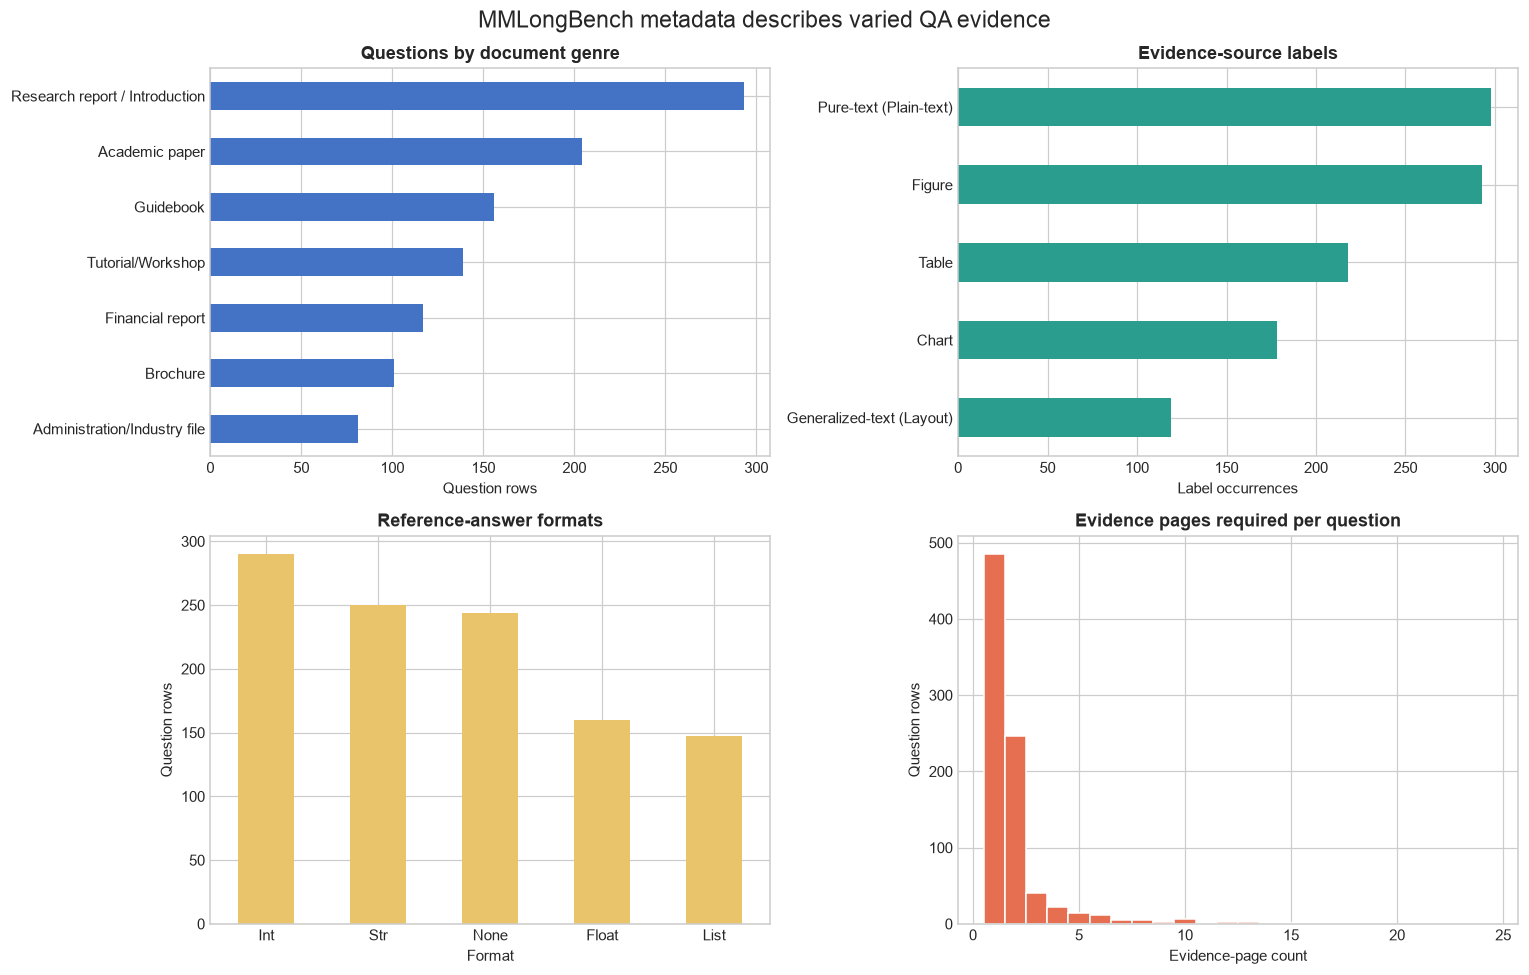

In [38]:
mmlong_evidence_sources = mmlong.explode("evidence_source_list")["evidence_source_list"].value_counts()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

mmlong["doc_type"].value_counts().sort_values().plot.barh(
    ax=axes[0, 0], color="#4472C4"
)
axes[0, 0].set_title("Questions by document genre")
axes[0, 0].set_xlabel("Question rows")
axes[0, 0].set_ylabel("")

mmlong_evidence_sources.sort_values().plot.barh(ax=axes[0, 1], color="#2A9D8F")
axes[0, 1].set_title("Evidence-source labels")
axes[0, 1].set_xlabel("Label occurrences")
axes[0, 1].set_ylabel("")

mmlong["answer_format"].value_counts().plot.bar(ax=axes[1, 0], color="#E9C46A")
axes[1, 0].set_title("Reference-answer formats")
axes[1, 0].set_xlabel("Format")
axes[1, 0].set_ylabel("Question rows")
axes[1, 0].tick_params(axis="x", rotation=0)

bins = np.arange(0.5, mmlong["evidence_page_count"].max() + 1.5, 1)
axes[1, 1].hist(mmlong["evidence_page_count"].dropna(), bins=bins, color="#E76F51", edgecolor="white")
axes[1, 1].set_title("Evidence pages required per question")
axes[1, 1].set_xlabel("Evidence-page count")
axes[1, 1].set_ylabel("Question rows")

fig.suptitle("MMLongBench metadata describes varied QA evidence", fontsize=15)
plt.tight_layout()
plt.show()

### Interpretation

MMLongBench is useful for long-document question answering because it includes reference answers and evidence pages across prose, tables, figures, charts, and layout-sensitive text. It is not currently a complete local document corpus: metadata-level exploration is complete, but end-to-end experiments are restricted to the one downloaded PDF.

**Question:** According to the report, how do 5% of the Latinos see economic upward mobility for their children?  **Reference answer:** Less well-off  **Stored evidence page:** 5  **Evidence source:** ['Chart']

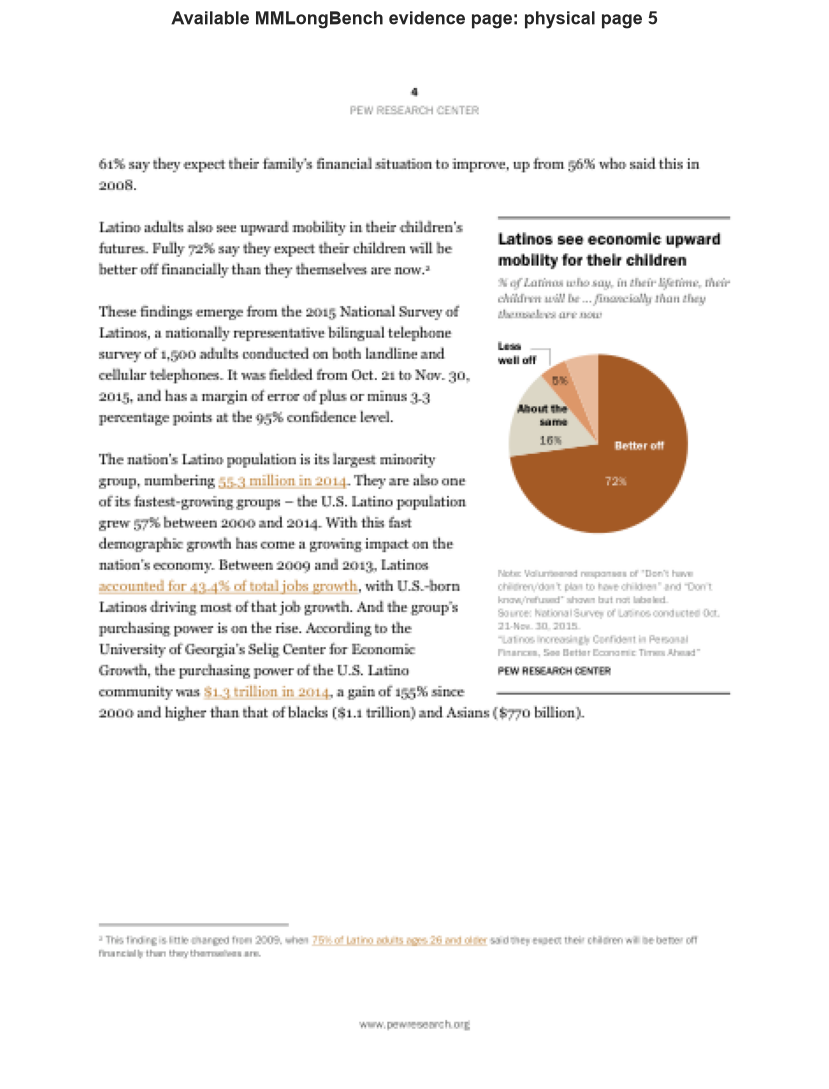

In [39]:
mmlong_sample = mmlong.iloc[0]
mmlong_sample_pdf = MMLONG_DIR / "documents" / mmlong_sample["doc_id"]
mmlong_evidence_page = int(mmlong_sample["evidence_page_list"][0])

display(
    Markdown(
        f"**Question:** {mmlong_sample['question']}  \
"
        f"**Reference answer:** {mmlong_sample['answer']}  \
"
        f"**Stored evidence page:** {mmlong_evidence_page}  \
"
        f"**Evidence source:** {mmlong_sample['evidence_source_list']}"
    )
)

if mmlong_sample_pdf.is_file():
    with pymupdf.open(mmlong_sample_pdf) as pdf:
        page = pdf[mmlong_evidence_page - 1]
        pixmap = page.get_pixmap(matrix=pymupdf.Matrix(0.75, 0.75), alpha=False)
    pixels = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(
        pixmap.height, pixmap.width, pixmap.n
    )
    fig, ax = plt.subplots(figsize=(8, 10))
    ax.imshow(pixels[:, :, :3])
    ax.set_title(f"Available MMLongBench evidence page: physical page {mmlong_evidence_page}")
    ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("The referenced PDF is not available locally.")

## 4. ViDoRe — queries and relevant document pages

ViDoRe separates the query table from the relevance table. One query can map to several relevant corpus pages, so joining the two tables expands the number of rows. The local cache contains queries and relevance judgments but no corpus page images.

In [40]:
vidore_queries = None
vidore_qrels = None
vidore_arrow_paths = sorted(VIDORE_DIR.rglob("*.arrow"))

for arrow_path in vidore_arrow_paths:
    frame = Dataset.from_file(str(arrow_path)).to_pandas()
    if "query" in frame.columns:
        vidore_queries = frame
    elif {"query_id", "corpus_id", "score"}.issubset(frame.columns):
        vidore_qrels = frame

assert vidore_queries is not None, "ViDoRe query table was not found"
assert vidore_qrels is not None, "ViDoRe relevance table was not found"

print("Query table shape:", vidore_queries.shape)
print("Relevance table shape:", vidore_qrels.shape)
display(vidore_queries.iloc[[0]].T.rename(columns={0: "stored value"}))
display(vidore_qrels.loc[vidore_qrels["query_id"] == vidore_queries.loc[0, "query_id"]].head(10))

Query table shape: (1920, 12)
Relevance table shape: (8808, 5)


,stored value
query_id,0
query,Quel était le montant total des rémunérations attribuées à tous les dirigeants de Christian Dior en 2023 ?
language,french
query_types,[numerical]
query_format,question
content_type,"[Table, Text]"
raw_answers,[Le montant total des rémunérations attribuées à tous les dirigeants de Christian Dior en 2023 était de 25 millions ...
query_generator,sdg
query_generation_pipeline,custom_pipeline
source_type,summary


,query_id,corpus_id,score,content_type,bounding_boxes
0,0,579,1,"[Table, Table, Text]","[{'annotator': 0, 'x1': 154, 'x2': 1586, 'y1': 688, 'y2': 1315}, {'annotator': 0, 'x1': 157, 'x2': 1577, 'y1': 1449,..."
1,0,580,1,"[Table, Table]","[{'annotator': 0, 'x1': 115, 'x2': 1545, 'y1': 259, 'y2': 919}, {'annotator': 0, 'x1': 115, 'x2': 1546, 'y1': 1115, ..."
2,0,582,1,[Table],"[{'annotator': 0, 'x1': 116, 'x2': 1541, 'y1': 386, 'y2': 1146}]"
3,0,585,1,[Table],"[{'annotator': 0, 'x1': 149, 'x2': 1582, 'y1': 1067, 'y2': 1679}]"
4,0,587,1,[Table],"[{'annotator': 0, 'x1': 107, 'x2': 1545, 'y1': 198, 'y2': 929}]"
5,0,659,2,[Table],"[{'annotator': 0, 'x1': 110, 'x2': 1543, 'y1': 1022, 'y2': 1281}]"
6,0,801,2,[Table],"[{'annotator': 0, 'x1': 147, 'x2': 1460, 'y1': 1090, 'y2': 1335}]"


### Reading the ViDoRe relationship

- query_id is the unique query key.
- corpus_id identifies a page in the absent corpus.
- score is a graded relevance label in the qrels table, not a model prediction.
- query_types describes the requested reasoning.
- content_type describes the visual or textual evidence involved.
- source_type and query_generator describe how the query was produced.

The first query has several qrel rows, demonstrating why the query table and relevance table have different grains.

In [41]:
vidore_query_ids = set(vidore_queries["query_id"])
vidore_qrel_query_ids = set(vidore_qrels["query_id"])
vidore_image_files = [
    path
    for path in VIDORE_DIR.rglob("*")
    if path.suffix.lower() in {".png", ".jpg", ".jpeg", ".webp"}
]

vidore_quality = pd.DataFrame(
    [
        {"check": "query rows", "value": len(vidore_queries)},
        {"check": "unique query IDs", "value": vidore_queries["query_id"].nunique()},
        {"check": "relevance rows", "value": len(vidore_qrels)},
        {"check": "unique corpus page IDs", "value": vidore_qrels["corpus_id"].nunique()},
        {"check": "duplicate query IDs", "value": int(vidore_queries["query_id"].duplicated().sum())},
        {
            "check": "exact duplicate qrels",
            "value": int(vidore_qrels.duplicated(subset=["query_id", "corpus_id", "score"]).sum()),
        },
        {"check": "qrels with missing query", "value": len(vidore_qrel_query_ids - vidore_query_ids)},
        {"check": "queries without qrels", "value": len(vidore_query_ids - vidore_qrel_query_ids)},
        {"check": "local corpus images", "value": len(vidore_image_files)},
    ]
)
display(vidore_quality)

pipeline_missingness = (
    vidore_queries.groupby("query_generator")["query_generation_pipeline"]
    .apply(lambda values: values.isna().mean())
    .rename("missing_pipeline_share")
)
display(pipeline_missingness.to_frame())

,check,value
0,query rows,1920
1,unique query IDs,1920
2,relevance rows,8808
3,unique corpus page IDs,883
4,duplicate query IDs,0
5,exact duplicate qrels,0
6,qrels with missing query,0
7,queries without qrels,0
8,local corpus images,0


,missing_pipeline_share
query_generator,
human,1.0
sdg,0.0


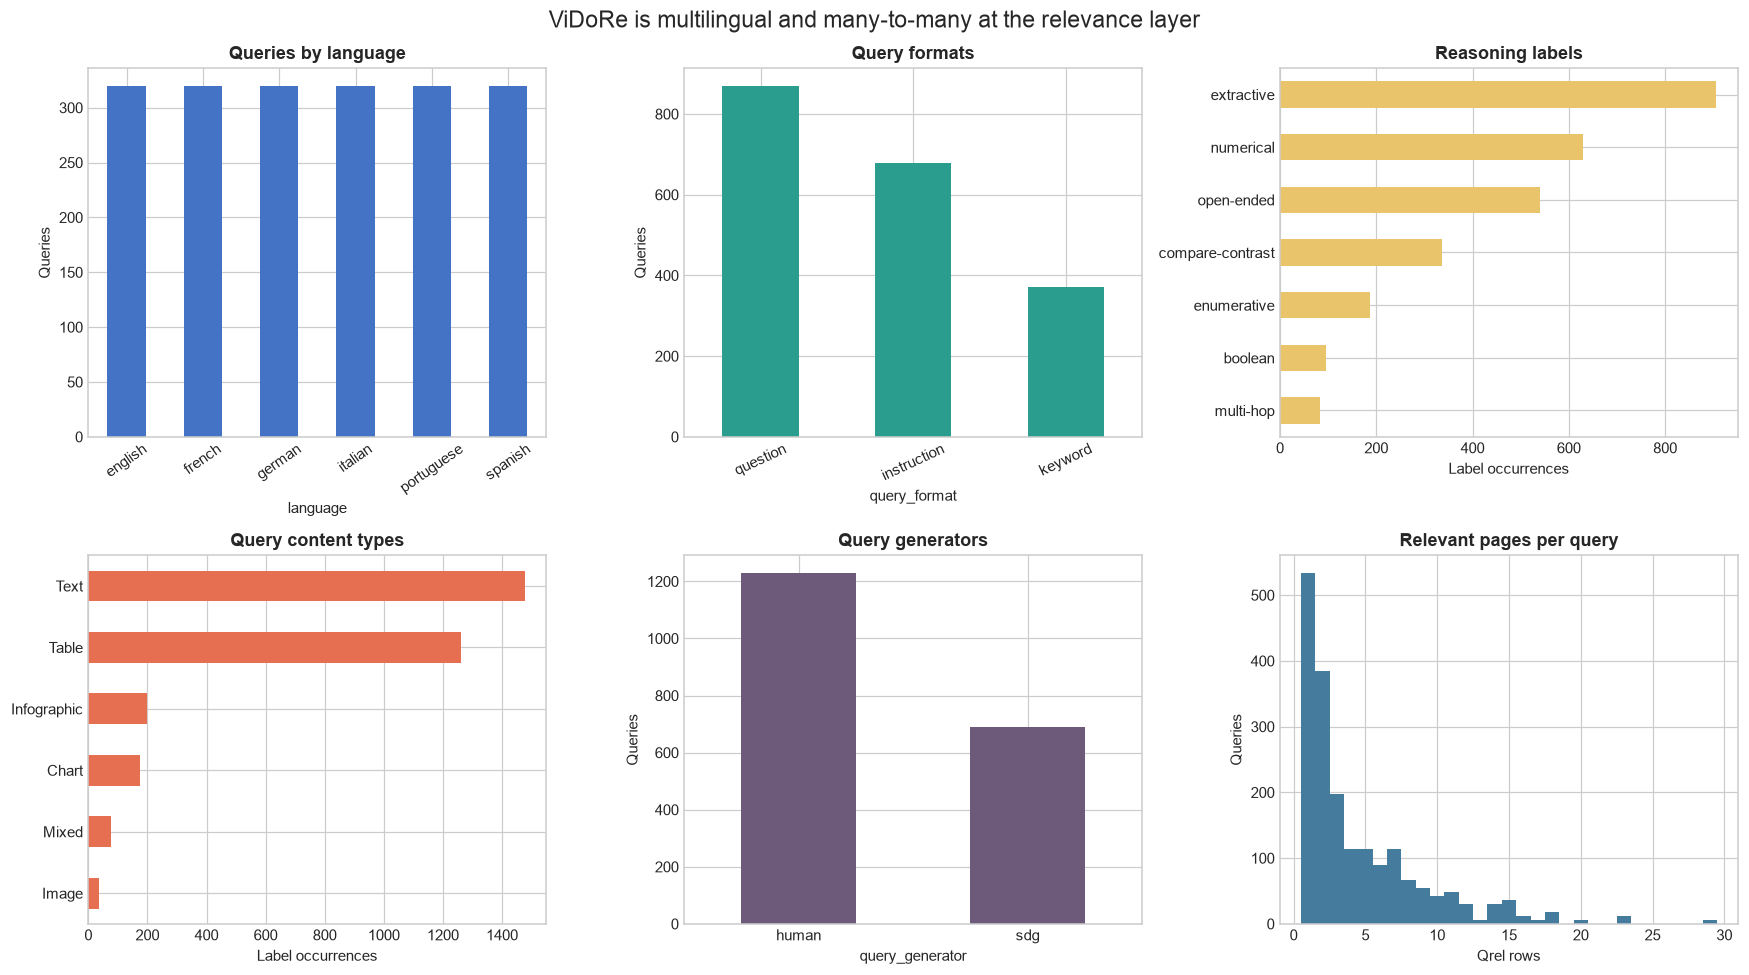

In [42]:
def flatten_sequence_column(series):
    values = []
    for item in series:
        if item is None:
            continue
        if isinstance(item, str):
            values.append(item)
        else:
            values.extend(list(item))
    return pd.Series(values, dtype="string")

vidore_query_types = flatten_sequence_column(vidore_queries["query_types"]).value_counts()
vidore_content_types = flatten_sequence_column(vidore_queries["content_type"]).value_counts()
qrels_per_query = vidore_qrels.groupby("query_id").size()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

vidore_queries["language"].value_counts().sort_index().plot.bar(ax=axes[0, 0], color="#4472C4")
axes[0, 0].set_title("Queries by language")
axes[0, 0].set_ylabel("Queries")
axes[0, 0].tick_params(axis="x", rotation=35)

vidore_queries["query_format"].value_counts().plot.bar(ax=axes[0, 1], color="#2A9D8F")
axes[0, 1].set_title("Query formats")
axes[0, 1].set_ylabel("Queries")
axes[0, 1].tick_params(axis="x", rotation=25)

vidore_query_types.sort_values().plot.barh(ax=axes[0, 2], color="#E9C46A")
axes[0, 2].set_title("Reasoning labels")
axes[0, 2].set_xlabel("Label occurrences")
axes[0, 2].set_ylabel("")

vidore_content_types.sort_values().plot.barh(ax=axes[1, 0], color="#E76F51")
axes[1, 0].set_title("Query content types")
axes[1, 0].set_xlabel("Label occurrences")
axes[1, 0].set_ylabel("")

vidore_queries["query_generator"].value_counts().plot.bar(ax=axes[1, 1], color="#6D597A")
axes[1, 1].set_title("Query generators")
axes[1, 1].set_ylabel("Queries")
axes[1, 1].tick_params(axis="x", rotation=0)

axes[1, 2].hist(qrels_per_query, bins=np.arange(0.5, qrels_per_query.max() + 1.5, 1), color="#457B9D")
axes[1, 2].set_title("Relevant pages per query")
axes[1, 2].set_xlabel("Qrel rows")
axes[1, 2].set_ylabel("Queries")

fig.suptitle("ViDoRe is multilingual and many-to-many at the relevance layer", fontsize=15)
plt.tight_layout()
plt.show()

### Interpretation

The equal language counts reflect a deliberately multilingual benchmark rather than the English-only scope of the current project MVP. The qrels are sufficient to study relevance structure and build evaluation code, but retrieval cannot be executed honestly until the referenced corpus pages are available.

## 5. OmniDocBench — pages decomposed into layout regions

One top-level record represents an annotated page. layout_dets contains regions such as text blocks, tables, figures, titles, and equations. Each region includes polygon coordinates and content fields when applicable.

In [43]:
omni_path = OMNI_DIR / "OmniDocBench.json"
with omni_path.open(encoding="utf-8") as file:
    omni_pages = json.load(file)

first_omni_page = omni_pages[0]
print("Annotated pages:", len(omni_pages))
display(pd.Series(first_omni_page["page_info"], name="stored value").to_frame())

first_regions_preview = []
for region in first_omni_page["layout_dets"][:3]:
    first_regions_preview.append(
        {
            "anno_id": region.get("anno_id"),
            "category_type": region.get("category_type"),
            "order": region.get("order"),
            "ignore": region.get("ignore"),
            "polygon": region.get("poly"),
            "text_or_latex": (region.get("text") or region.get("latex") or "")[:160],
        }
    )
display(pd.DataFrame(first_regions_preview))

Annotated pages: 1651


,stored value
page_no,0
height,2339
width,1653
image_path,page-d1561665-5359-42fe-920c-d6e3bff81953.png
page_attribute,"{'data_source': 'book', 'language': 'english', 'layout': 'single_column', 'special_issue': [], 'subset': 'equation_h..."


,anno_id,category_type,order,ignore,polygon,text_or_latex
0,box_id_0,text_block,2,False,"[268.9431, 319.9752, 322.9962, 319.9752, 322.9962, 351.0839, 268.9431, 351.0839]",that
1,box_id_1,equation_isolated,3,False,"[404.985, 362.0772, 816.987183, 362.0772, 816.987183, 448.324432, 404.985, 448.324432]",$$AB = \n\left[\begin{array}{ccc}\n2 & 3 \\\n1 & 4\n\end{array}\right]\n\left[\begin{array}{ccc}\n5 & 2 & 1 \\\n3 & ...
2,box_id_2,text_block,5,False,"[271.9185, 551.0684, 1379.9244, 551.0684, 1379.9244, 698.8932, 271.9185, 698.8932]","When an attempt is made to form the product $ \mathbf{{BA}} $ , we discover that the dimensions are not compatible i..."


### Reading an OmniDocBench record

page_info supplies the page dimensions, source category, language, layout, subset, and referenced image path. Each layout detection has an annotation ID, semantic category, reading order, polygon, and sometimes text or LaTeX. The polygons use the coordinate system of the missing page image.

In [44]:
omni_page_rows = []
omni_region_rows = []

for page_index, page_record in enumerate(omni_pages):
    page_info = page_record.get("page_info", {})
    attributes = page_info.get("page_attribute", {})
    omni_page_rows.append(
        {
            "page_index": page_index,
            "sample_id": page_info.get("sample_id"),
            "page_no": page_info.get("page_no"),
            "width": page_info.get("width"),
            "height": page_info.get("height"),
            "image_path": page_info.get("image_path"),
            "data_source": attributes.get("data_source"),
            "language": attributes.get("language"),
            "layout": attributes.get("layout"),
            "subset": attributes.get("subset"),
            "region_count": len(page_record.get("layout_dets", [])),
        }
    )
    for region in page_record.get("layout_dets", []):
        polygon = region.get("poly")
        omni_region_rows.append(
            {
                "page_index": page_index,
                "anno_id": region.get("anno_id"),
                "category_type": region.get("category_type"),
                "ignore": region.get("ignore"),
                "order": region.get("order"),
                "polygon_coordinate_count": len(polygon) if isinstance(polygon, list) else np.nan,
                "has_text": bool(region.get("text")),
                "has_latex": bool(region.get("latex")),
            }
        )

omni_page_table = pd.DataFrame(omni_page_rows)
omni_region_table = pd.DataFrame(omni_region_rows)
print("Page table shape:", omni_page_table.shape)
print("Region table shape:", omni_region_table.shape)
display(omni_page_table.head(3))
display(omni_region_table.head(5))

Page table shape: (1651, 11)
Region table shape: (32798, 8)


,page_index,sample_id,page_no,width,height,image_path,data_source,language,layout,subset,region_count
0,0,NaN,0,1653,2339,page-d1561665-5359-42fe-920c-d6e3bff81953.png,book,english,single_column,equation_hard,16
1,1,NaN,0,1653,2339,page-bd6eb36e-0856-4d9d-b587-21b4a0209c8b.png,academic_literature,english,single_column,equation_hard,10
2,2,NaN,0,1700,2200,page-affbb0cc-d616-481d-b493-80ed1ccb5a10.png,book,simplified_chinese,single_column,equation_hard,7


,page_index,anno_id,category_type,ignore,order,polygon_coordinate_count,has_text,has_latex
0,0,box_id_0,text_block,False,2.0,8,True,False
1,0,box_id_1,equation_isolated,False,3.0,8,False,True
2,0,box_id_2,text_block,False,5.0,8,True,False
3,0,box_id_3,text_block,False,6.0,8,True,False
4,0,box_id_4,text_block,False,7.0,8,True,False


In [45]:
omni_local_images = {
    path.name
    for path in OMNI_DIR.rglob("*")
    if path.suffix.lower() in {".png", ".jpg", ".jpeg"}
}
omni_referenced_images = set(omni_page_table["image_path"].dropna())
invalid_polygon_rows = int(
    ((omni_region_table["polygon_coordinate_count"] < 8)
     | (omni_region_table["polygon_coordinate_count"] % 2 != 0)
     | omni_region_table["polygon_coordinate_count"].isna()).sum()
)
duplicate_annotation_ids = int(
    omni_region_table.duplicated(subset=["page_index", "anno_id"]).sum()
)

omni_quality = pd.DataFrame(
    [
        {"check": "annotated pages", "value": len(omni_page_table)},
        {"check": "layout regions", "value": len(omni_region_table)},
        {"check": "semantic categories", "value": omni_region_table["category_type"].nunique()},
        {"check": "pages missing sample_id", "value": int(omni_page_table["sample_id"].isna().sum())},
        {"check": "invalid polygon rows", "value": invalid_polygon_rows},
        {"check": "duplicate annotation IDs within page", "value": duplicate_annotation_ids},
        {"check": "referenced page images", "value": len(omni_referenced_images)},
        {
            "check": "referenced images available locally",
            "value": len(omni_referenced_images & omni_local_images),
        },
    ]
)
display(omni_quality)

,check,value
0,annotated pages,1651
1,layout regions,32798
2,semantic categories,28
3,pages missing sample_id,296
4,invalid polygon rows,0
5,duplicate annotation IDs within page,0
6,referenced page images,1651
7,referenced images available locally,0


### Actual annotation geometry without the missing page image

The next plot uses the real polygon coordinates from the first record. It is not a reconstructed document page: the blank background makes the missing image explicit while still revealing the spatial annotation structure.

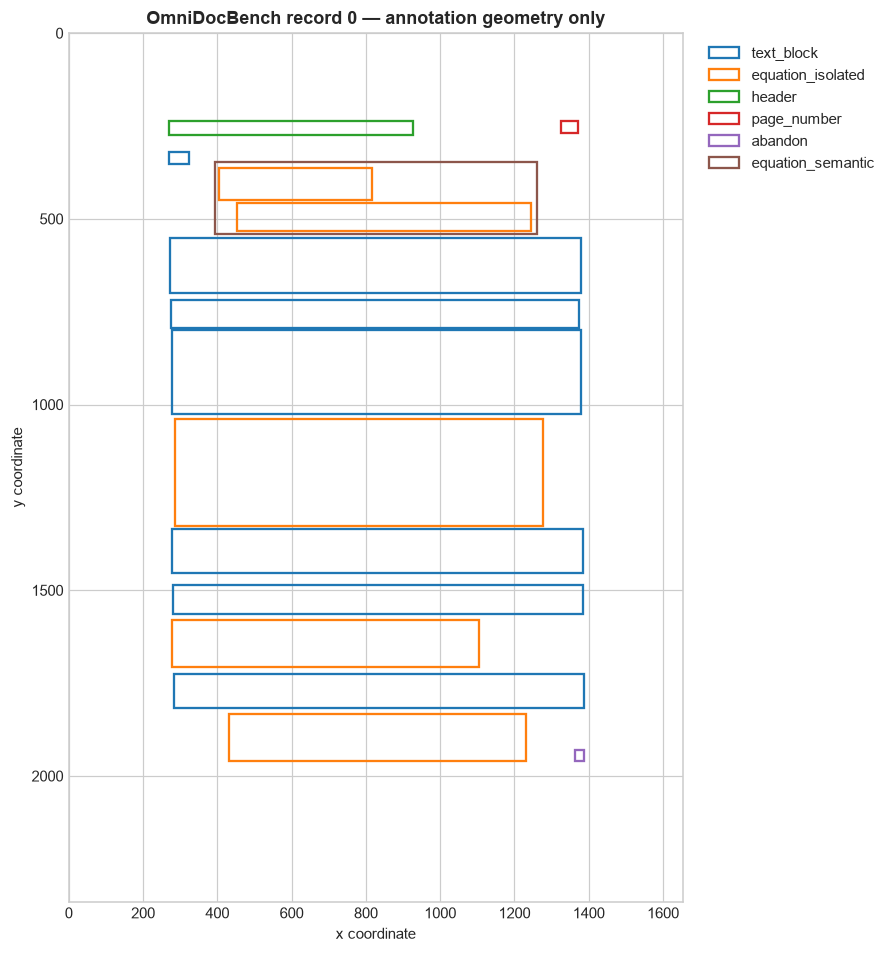

In [46]:
geometry_page = omni_pages[0]
geometry_info = geometry_page["page_info"]
geometry_categories = [region["category_type"] for region in geometry_page["layout_dets"]]
category_palette = {
    category: plt.cm.tab10(index % 10)
    for index, category in enumerate(dict.fromkeys(geometry_categories))
}

fig, ax = plt.subplots(figsize=(8, 11))
for region in geometry_page["layout_dets"]:
    coordinates = np.asarray(region["poly"], dtype=float).reshape(-1, 2)
    patch = Polygon(
        coordinates,
        closed=True,
        fill=False,
        linewidth=1.5,
        edgecolor=category_palette[region["category_type"]],
        label=region["category_type"],
    )
    ax.add_patch(patch)

ax.set_xlim(0, geometry_info["width"])
ax.set_ylim(geometry_info["height"], 0)
ax.set_aspect("equal")
ax.set_title("OmniDocBench record 0 — annotation geometry only")
ax.set_xlabel("x coordinate")
ax.set_ylabel("y coordinate")
handles, labels = ax.get_legend_handles_labels()
unique_legend = dict(zip(labels, handles))
ax.legend(unique_legend.values(), unique_legend.keys(), loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

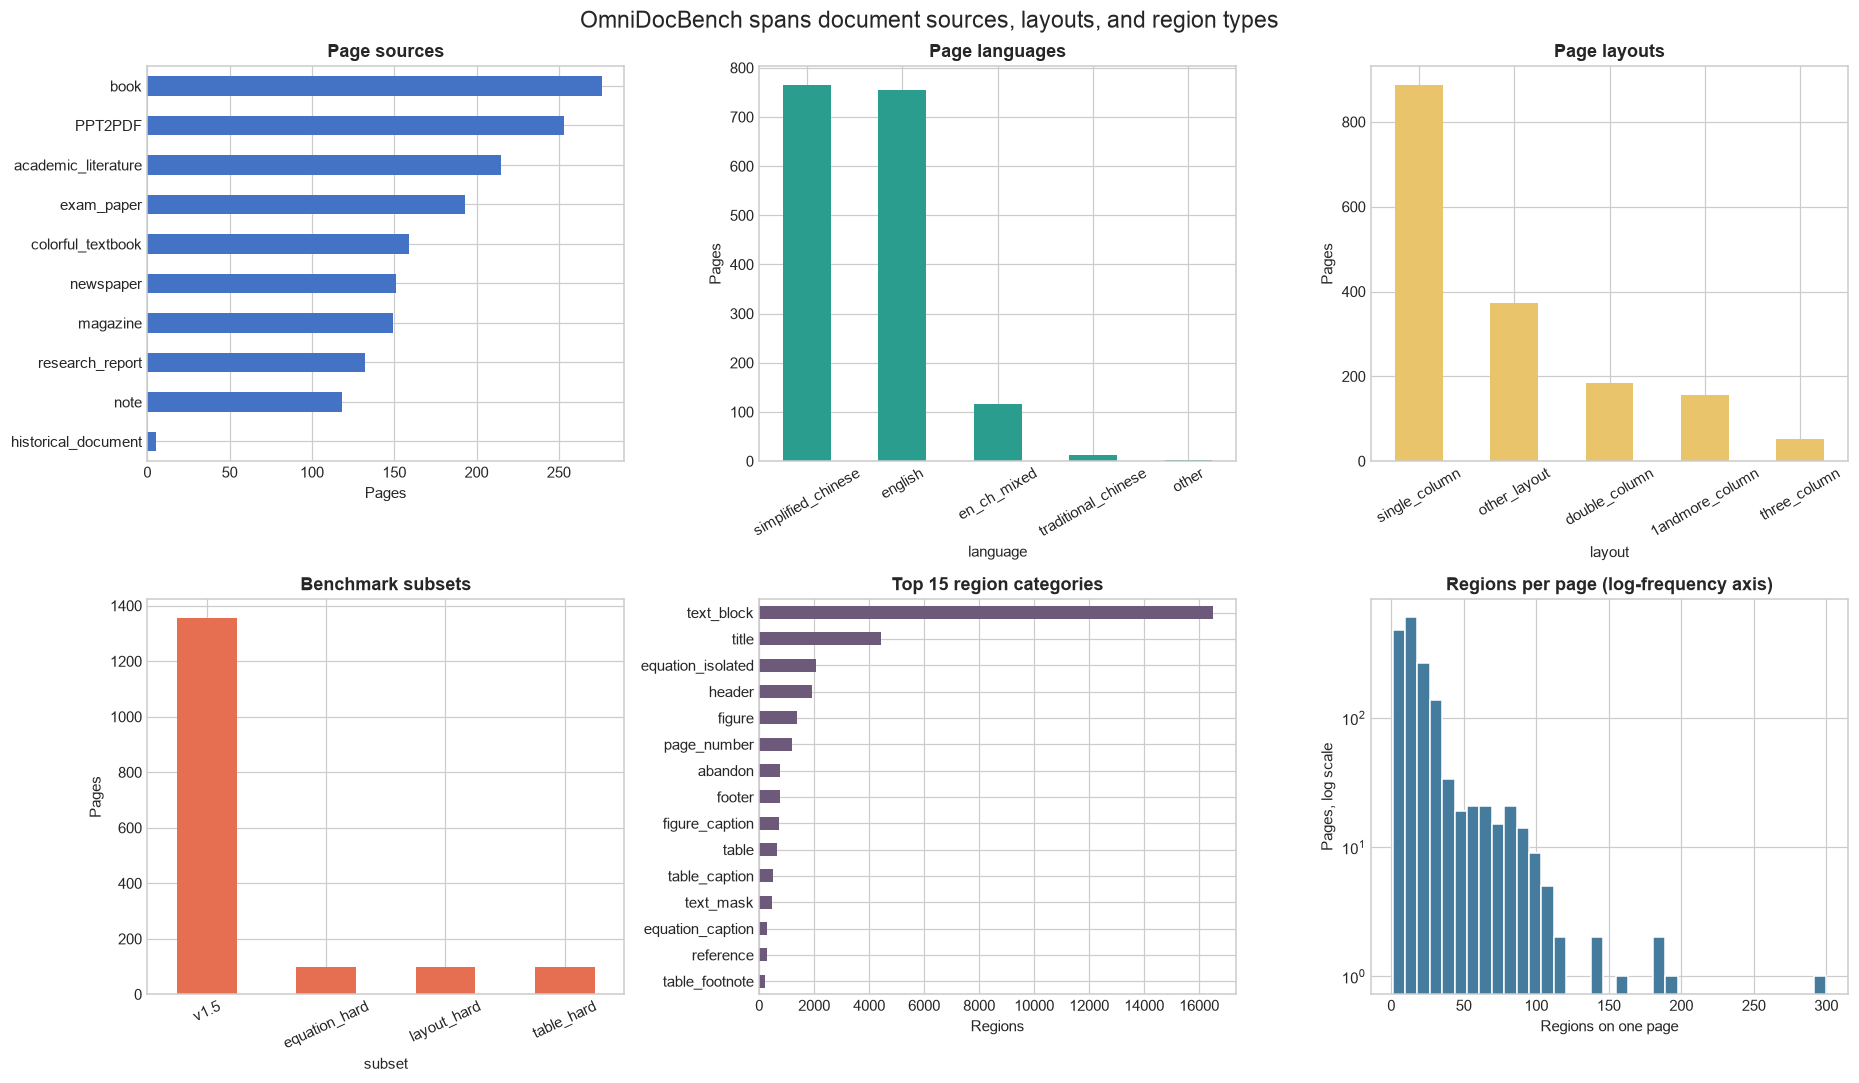

In [47]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

omni_page_table["data_source"].value_counts().sort_values().plot.barh(ax=axes[0, 0], color="#4472C4")
axes[0, 0].set_title("Page sources")
axes[0, 0].set_xlabel("Pages")
axes[0, 0].set_ylabel("")

omni_page_table["language"].value_counts().plot.bar(ax=axes[0, 1], color="#2A9D8F")
axes[0, 1].set_title("Page languages")
axes[0, 1].set_ylabel("Pages")
axes[0, 1].tick_params(axis="x", rotation=30)

omni_page_table["layout"].value_counts().plot.bar(ax=axes[0, 2], color="#E9C46A")
axes[0, 2].set_title("Page layouts")
axes[0, 2].set_ylabel("Pages")
axes[0, 2].tick_params(axis="x", rotation=30)

omni_page_table["subset"].value_counts().plot.bar(ax=axes[1, 0], color="#E76F51")
axes[1, 0].set_title("Benchmark subsets")
axes[1, 0].set_ylabel("Pages")
axes[1, 0].tick_params(axis="x", rotation=25)

omni_region_table["category_type"].value_counts().head(15).sort_values().plot.barh(
    ax=axes[1, 1], color="#6D597A"
)
axes[1, 1].set_title("Top 15 region categories")
axes[1, 1].set_xlabel("Regions")
axes[1, 1].set_ylabel("")

axes[1, 2].hist(omni_page_table["region_count"], bins=35, color="#457B9D", edgecolor="white")
axes[1, 2].set_yscale("log")
axes[1, 2].set_title("Regions per page (log-frequency axis)")
axes[1, 2].set_xlabel("Regions on one page")
axes[1, 2].set_ylabel("Pages, log scale")

fig.suptitle("OmniDocBench spans document sources, layouts, and region types", fontsize=15)
plt.tight_layout()
plt.show()

### Interpretation

OmniDocBench is region-level parsing data, not a question-answering dataset. Its annotations cover many semantic structures and deliberately difficult equation, table, and layout subsets. The annotation JSON is enough to study labels and geometry, but image-based parsing evaluation requires the referenced page images.

## 6. Compare meanings instead of matching column names

Several datasets label evidence, but their vocabularies describe different objects. The comparison below prevents silent label substitution.

In [48]:
label_comparison = pd.DataFrame(
    [
        {
            "dataset": "Local project annotations",
            "field": "evidence_modality",
            "describes": "where a human must look to answer a question",
            "observed/examples": "text, table, figure, equation, scanned_text, multiple",
        },
        {
            "dataset": "MMLongBench-Doc",
            "field": "evidence_sources",
            "describes": "source form associated with QA evidence",
            "observed/examples": ", ".join(map(str, mmlong_evidence_sources.index.tolist())),
        },
        {
            "dataset": "ViDoRe",
            "field": "content_type",
            "describes": "content involved in a retrieval query or relevant page",
            "observed/examples": ", ".join(map(str, vidore_content_types.index.tolist())),
        },
        {
            "dataset": "OmniDocBench",
            "field": "category_type",
            "describes": "semantic class of one annotated page region",
            "observed/examples": ", ".join(omni_region_table["category_type"].value_counts().head(8).index),
        },
    ]
)
display(label_comparison)

,dataset,field,describes,observed/examples
0,Local project annotations,evidence_modality,where a human must look to answer a question,"text, table, figure, equation, scanned_text, multiple"
1,MMLongBench-Doc,evidence_sources,source form associated with QA evidence,"Pure-text (Plain-text), Figure, Table, Chart, Generalized-text (Layout)"
2,ViDoRe,content_type,content involved in a retrieval query or relevant page,"Text, Table, Infographic, Chart, Mixed, Image"
3,OmniDocBench,category_type,semantic class of one annotated page region,"text_block, title, equation_isolated, header, figure, page_number, abandon, footer"


## 7. Evidence-backed role for each dataset

A dataset is usable for a task only when both its labels and the required underlying assets are available.

In [49]:
dataset_roles = pd.DataFrame(
    [
        {
            "dataset": "Local project corpus",
            "grain": "document / verified question",
            "best project role": "primary controlled QA evaluation",
            "available now": f"{len(documents)} PDFs registered and inspectable",
            "readiness gate": f"{len(verified_questions)} verified questions; select documents and annotate first",
        },
        {
            "dataset": "MMLongBench-Doc",
            "grain": "question about one document",
            "best project role": "external long-document QA and evidence benchmark",
            "available now": f"{len(mmlong):,} question rows and {len(mmlong_pdf_names)} local PDF",
            "readiness gate": f"{len(mmlong_referenced_documents) - len(mmlong_referenced_documents & mmlong_pdf_names)} referenced PDFs absent",
        },
        {
            "dataset": "ViDoRe",
            "grain": "query / query–page relevance row",
            "best project role": "external page-retrieval evaluation",
            "available now": f"{len(vidore_queries):,} queries and {len(vidore_qrels):,} qrels",
            "readiness gate": f"{len(vidore_image_files)} local corpus images",
        },
        {
            "dataset": "OmniDocBench",
            "grain": "page / page region",
            "best project role": "external parsing and layout evaluation",
            "available now": f"{len(omni_page_table):,} pages and {len(omni_region_table):,} region annotations",
            "readiness gate": f"{len(omni_referenced_images & omni_local_images)} of {len(omni_referenced_images)} referenced images local",
        },
    ]
)
display(dataset_roles)

,dataset,grain,best project role,available now,readiness gate
0,Local project corpus,document / verified question,primary controlled QA evaluation,3 PDFs registered and inspectable,0 verified questions; select documents and annotate first
1,MMLongBench-Doc,question about one document,external long-document QA and evidence benchmark,"1,091 question rows and 1 local PDF",134 referenced PDFs absent
2,ViDoRe,query / query–page relevance row,external page-retrieval evaluation,"1,920 queries and 8,808 qrels",0 local corpus images
3,OmniDocBench,page / page region,external parsing and layout evaluation,"1,651 pages and 32,798 region annotations",0 of 1651 referenced images local


## Validation — distinguish invalid data from incomplete data

Structural errors should stop the notebook. Expected incompleteness—such as an empty verified-question set or absent optional benchmark media—should remain a visible readiness gate.

In [50]:
required_document_columns = {
    "doc_id", "file_path", "title", "source_kind", "page_count", "status"
}
required_question_columns = {
    "question_id", "doc_id", "question", "evidence_pages", "status"
}

assert inventory["exists"].all(), "A primary local metadata asset is missing"
assert required_document_columns.issubset(documents.columns)
assert required_question_columns.issubset(questions.columns)
assert documents["doc_id"].is_unique, "Local document IDs are not unique"
assert questions["question_id"].is_unique, "Local question IDs are not unique"
assert set(questions["doc_id"].dropna()).issubset(set(documents["doc_id"]))
assert local_document_check["file_exists"].all(), "A registered project PDF is missing"
assert (local_document_check["declared_pages"] == local_document_check["observed_pages"]).all()
assert mmlong_parse_failures == 0, "MMLongBench evidence lists did not all parse"
assert vidore_queries["query_id"].is_unique, "ViDoRe query IDs are not unique"
assert not (vidore_qrel_query_ids - vidore_query_ids), "A ViDoRe qrel references a missing query"
assert not (vidore_query_ids - vidore_qrel_query_ids), "A ViDoRe query has no relevance row"
assert invalid_polygon_rows == 0, "OmniDocBench contains malformed polygons"
assert duplicate_annotation_ids == 0, "OmniDocBench annotation IDs repeat within a page"

print("Structural validation passed.")
print("Expected readiness gates remain visible in the role matrix above.")

Structural validation passed.
Expected readiness gates remain visible in the role matrix above.


## Interpretation and next step

The project is not working with one large interchangeable dataset. It has a project-specific evaluation corpus plus three external benchmarks aimed at different pipeline stages.

1. Use the local PDFs to learn and build the pipeline because their content can be inspected directly.
2. Select local documents and create human-verified questions before claiming project QA performance.
3. Use MMLongBench later for external long-document QA checks after the needed PDFs are available.
4. Use ViDoRe for retrieval evaluation only after obtaining its corpus pages.
5. Use OmniDocBench for parsing/layout evaluation only after obtaining the referenced images.

The immediate next step is therefore annotation, not model scoring: select the local documents, write a small balanced dev set, and verify each answer and evidence page against the rendered PDF.